# 04 · Quantization-aware training: soft staircase vs STE

PTQ broke down at 2–3 bits (notebook 03). Now we **train through the quantizer** and compare, under exactly the same
budget, the classic STE recipe with the vvtk_quant soft staircase.

| Step | What you will see |
|---|---|
| 1 | the fair protocol (and the mistake of the v0.x notebooks) |
| 2 | the five contenders |
| 3 | training, with the **hard** model evaluated every epoch |
| 4 | accuracy curves and final table |
| 5 | oscillation: how many weights change level per epoch |
| 6 | where the weights end up: distance to the nearest level |

**Tags** (see notebook 00): 📘 common practice · 📗 known, less common · 🧪 new or modified in vvtk_quant.

In [4]:
import os, sys, copy, math, time
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from vvtk_quant import VVTK_QModel
from vvtk_quant.quant import nearest_index
from common_cifar import DEVICE, loaders, evaluate, train_epoch, pretrained_fp32
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
train_loader, test_loader = loaders()
fp32 = pretrained_fp32(train_loader, test_loader, epochs=5)
acc_fp32 = evaluate(fp32, test_loader)
print(f"fp32 after 5 epochs: {acc_fp32:.2f}%")

loaded /extra/scratch05/alumno1/vvtk_quant/examples/out/cifar_fp32_e5_s0.pth


/extra/scratch05/alumno1/vvtk_quant/examples/common_cifar.py:140: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(path, map_location=DEVICE))


fp32 after 5 epochs: 68.68%


## Step 1 · A fair protocol

The v0.x notebooks trained the float model 5 epochs, then ran 3 epochs of QAT, and compared the QAT model with the
5-epoch float model. QAT sometimes came out **better than float** (e.g. 74.3 % vs 72.5 % in the old notebook 7): not
because quantization helps, but because QAT got 3 more epochs of training. Also, the accuracy printed during QAT was
the one of the *soft* model.

Here every contender, including a float one, starts from the same 5-epoch checkpoint and gets the **same 3 epochs,
same optimizer, same learning-rate schedule**. Every number is the **hard** (deployed) model.

$$\text{budget: } 3 \text{ epochs, Adam}, \ \eta_t = \eta_0 \cdot \tfrac12\big(1+\cos(\pi t / t_{\max})\big), \ \eta_0 = 3\cdot 10^{-4} .$$

> 📘 **Common practice (good practice).** Equal budgets and hard evaluation are what reviewers expect. Fine-tuning QAT
> from a float checkpoint is the standard recipe (Nagel et al. white paper, arXiv:2106.08295, §4).

In [5]:
EPOCHS, LR = 3, 3e-4
BITS = [3, 2]
steps_per_epoch = len(train_loader)
total_steps = EPOCHS * steps_per_epoch

## Step 2 · The contenders

| name | levels | forward | backward |
|---|---|---|---|
| `fp32` | none | float | exact |
| `ste-uniform` | uniform absmax (int-$b$) | $Q(w)$ | 1 (STE) |
| `ste-lloyd` | Lloyd-Max | $Q(w)$ | 1 (STE) |
| `soft-lloyd` | Lloyd-Max | $Q_T(w)$, $T: 2 \to 40$ | $Q_T'(w)$ |
| `soft-lloyd+anchor` | Lloyd-Max | $Q_T(w)$ | $Q_T'(w) + \lambda\, \partial A/\partial w$ (fused in the layer) |

`ste-lloyd` separates the two ingredients of vvtk_quant: **where the levels are** (uniform vs Lloyd) and **how the
gradient crosses the staircase** (STE vs soft). The anchor is
$A=\operatorname{mean}\big((w-Q(w))/\Delta(w)\big)^2$ (distance to the nearest level in units of the local step), applied
inside each layer's backward pass with $\lambda = 1$.

The temperature follows a geometric anneal per step: $T_t = T_0 (T_1/T_0)^{t/t_{\max}}$.

| contender | tag |
|---|---|
| `fp32`, `ste-uniform` | 📘 the standard baselines |
| `ste-lloyd` | 📘 pieces (STE, Lloyd levels), 🧪 as an experimental control |
| `soft-lloyd` | 📗 soft staircase (DSQ-like) + 🧪 non-uniform levels, relative $T$ |
| `soft-lloyd+anchor` | 🧪 the vvtk_quant recipe (anchor related to ProxQuant 📗) |

A stronger 📘 baseline you should add: LSQ (arXiv:1902.08153), exercise 3 below.

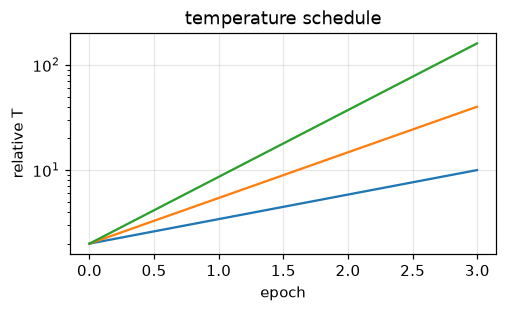

In [6]:
T0, T1 = 2.0, [10.0,40.0,160.0]
CONTENDERS = {
    "fp32":              dict(mode=None),
    "ste-uniform":       dict(mode="ste", method="uniform"),
    "ste-lloyd":         dict(mode="ste", method="lloyd"),
    "soft-lloyd":        dict(mode="soft", method="lloyd"),
    "soft-lloyd+anchor": dict(mode="soft", method="lloyd", anchor="weight", anchor_lambda=1.0),
}
ts = np.arange(total_steps)
plt.figure(figsize=(5, 2.6));
for t1 in T1:
    plt.semilogy(ts / steps_per_epoch, T0 * (t1 / T0) ** (ts / (total_steps - 1)))
plt.xlabel("epoch"); plt.ylabel("relative T"); plt.title("temperature schedule"); plt.show()

## Step 3 · Training

One function runs one contender. Besides accuracy it records, at the end of every epoch, the level index of every
weight, so we can count how many weights **changed level** during the epoch (oscillation, Step 5).

In [8]:
def level_indices(q):
    return torch.cat([nearest_index(m.weight, m.levels_weight).flatten() for m in q.qmodules()])

def run(name, b, seed=0, T1_value=None):
    cfg = dict(CONTENDERS[name]); mode = cfg.pop("mode"); method = cfg.pop("method", None)
    torch.manual_seed(seed)
    model = copy.deepcopy(fp32)
    if mode is None:
        q = model
    else:
        q = VVTK_QModel(model, b=b, module_types=[nn.Conv2d, nn.Linear], mode=mode, temp=T0, **cfg)
        q.calibrate_quant(method=method)
    opt = torch.optim.Adam(q.parameters(), LR)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: 0.5 * (1 + math.cos(math.pi * t / total_steps)))
    step = [0]
    def hook():
        if mode == "soft":
            q.update_temp(T0 * (T1_value / T0) ** (step[0] / (total_steps - 1)))
        step[0] += 1
    hist = {"acc": [evaluate(q, test_loader)], "flips": []}
    prev = level_indices(q) if mode else None
    for ep in range(EPOCHS):
        loss, dt = train_epoch(q, train_loader, opt, sched, step_hook=hook)
        hist["acc"].append(evaluate(q, test_loader))
        if mode:
            cur = level_indices(q)
            hist["flips"].append((cur != prev).float().mean().item()); prev = cur
        print(f"  {name:<18} b={b} epoch {ep + 1}: loss {loss:.3f}  hard test acc {hist['acc'][-1]:5.2f}%  ({dt:.0f}s)")
    hist["dist"] = q.distance_to_level().cpu().numpy() if mode else None
    return hist

H = {}
for b in BITS:
    for name in CONTENDERS:
        if name == "fp32":
            H[(name, b)] = run(name, b)
            continue
        if name in ("soft-lloyd", "soft-lloyd+anchor"):
            for t1 in T1:
                print(f"Entrenando {name}, {b} bits, T1={t1}")
                H[(name, b, t1)] = run(name, b, T1_value=t1)
        else:
            H[(name, b)] = run(name, b)

  fp32               b=3 epoch 1: loss 0.609  hard test acc 79.38%  (4s)
  fp32               b=3 epoch 2: loss 0.546  hard test acc 81.26%  (4s)
  fp32               b=3 epoch 3: loss 0.502  hard test acc 81.94%  (4s)
  ste-uniform        b=3 epoch 1: loss 0.692  hard test acc 77.33%  (9s)
  ste-uniform        b=3 epoch 2: loss 0.612  hard test acc 78.67%  (8s)
  ste-uniform        b=3 epoch 3: loss 0.558  hard test acc 80.21%  (8s)
  ste-lloyd          b=3 epoch 1: loss 0.641  hard test acc 78.60%  (8s)
  ste-lloyd          b=3 epoch 2: loss 0.576  hard test acc 80.16%  (8s)
  ste-lloyd          b=3 epoch 3: loss 0.528  hard test acc 81.47%  (8s)
Entrenando soft-lloyd, 3 bits, T1=10.0
  soft-lloyd         b=3 epoch 1: loss 0.618  hard test acc 60.01%  (16s)
  soft-lloyd         b=3 epoch 2: loss 0.549  hard test acc 71.45%  (15s)
  soft-lloyd         b=3 epoch 3: loss 0.507  hard test acc 76.48%  (16s)
Entrenando soft-lloyd, 3 bits, T1=40.0
  soft-lloyd         b=3 epoch 1: loss 0.62

## Step 4 · Results

/tmp/ipykernel_1554813/1471874825.py:10: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(range(EPOCHS + 1),acc,"o-",label=name,ls="--" if name == "fp32" else "-")


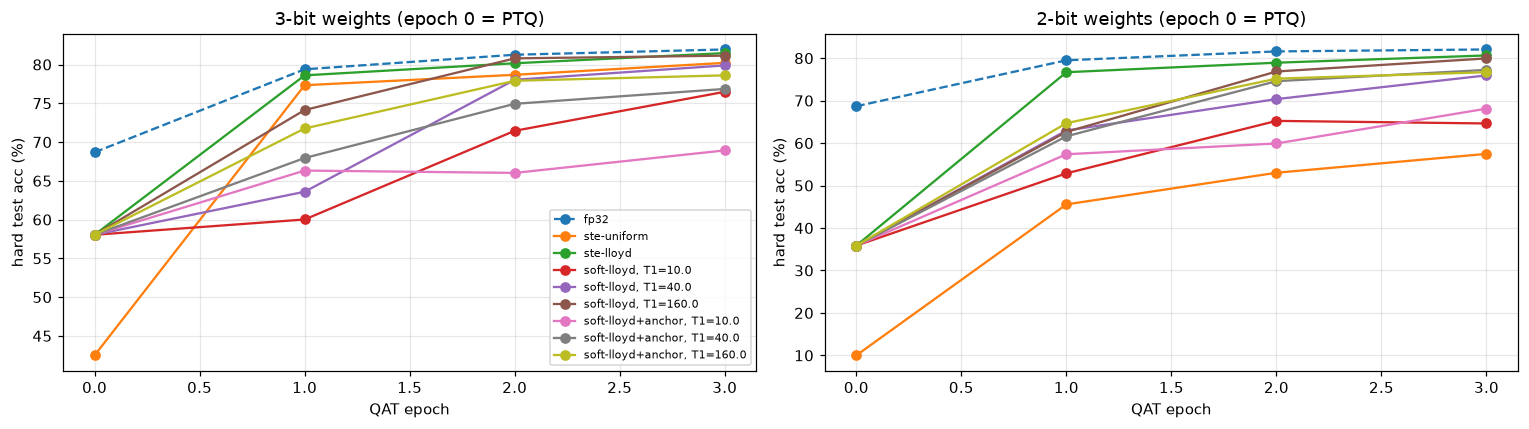

contender                 | 3-bit PTQ -> QAT | 2-bit PTQ -> QAT
-------------------------------------------------------------------------------------
fp32                      |  68.68 ->  81.94 |  68.68 ->  82.05
ste-uniform               |  42.49 ->  80.21 |  10.01 ->  57.46
ste-lloyd                 |  58.04 ->  81.47 |  35.86 ->  80.64
soft-lloyd (T1=10.0 ) |  58.04 ->  76.48 |  35.86 ->  64.62
soft-lloyd (T1=40.0 ) |  58.04 ->  79.88 |  35.86 ->  75.95
soft-lloyd (T1=160.0) |  58.04 ->  81.14 |  35.86 ->  79.94
soft-lloyd+anchor (T1=10.0 ) |  58.04 ->  68.92 |  35.86 ->  68.11
soft-lloyd+anchor (T1=40.0 ) |  58.04 ->  76.85 |  35.86 ->  77.23
soft-lloyd+anchor (T1=160.0) |  58.04 ->  78.60 |  35.86 ->  76.69


In [9]:
fig, axs = plt.subplots(1, len(BITS), figsize=(14, 4), sharey=False)
for ax, b in zip(axs, BITS):
    for name in CONTENDERS:
        if name in ("soft-lloyd", "soft-lloyd+anchor"):
            for t1 in T1:
                acc = H[(name, b, t1)]["acc"]
                ax.plot(range(EPOCHS + 1),acc,"o-",label=f"{name}, T1={t1}")
        else:
            acc = H[(name, b)]["acc"]
            ax.plot(range(EPOCHS + 1),acc,"o-",label=name,ls="--" if name == "fp32" else "-")
    ax.set_title(f"{b}-bit weights (epoch 0 = PTQ)")
    ax.set_xlabel("QAT epoch")
    ax.set_ylabel("hard test acc (%)")
    ax.grid(alpha=0.3)
axs[0].legend(fontsize=7, loc="best")
plt.tight_layout()
plt.show()
print(f"{'contender':<25} | " + " | ".join(f"{b}-bit PTQ -> QAT" for b in BITS))
print("-" * 85)
for name in CONTENDERS:
    if name in ("soft-lloyd", "soft-lloyd+anchor"):
        for t1 in T1:
            print(f"{name} (T1={t1:<5}) | " +" | ".join(f"{H[(name, b, t1)]['acc'][0]:6.2f} -> "f"{H[(name, b, t1)]['acc'][-1]:6.2f}"for b in BITS))
    else:
        print(f"{name:<25} | " +" | ".join(f"{H[(name, b)]['acc'][0]:6.2f} -> "f"{H[(name, b)]['acc'][-1]:6.2f}"for b in BITS))


## Step 5 · Oscillation

> 📗 **Known, less common**: measuring oscillations is from Nagel et al. 2022 (arXiv:2203.11086).

Fraction of quantized weights whose level index changed during each epoch. STE weights sit near limits and keep
crossing them; with the soft staircase the latent weights are pushed into bins as $T$ grows; the anchor pulls them
onto the levels.

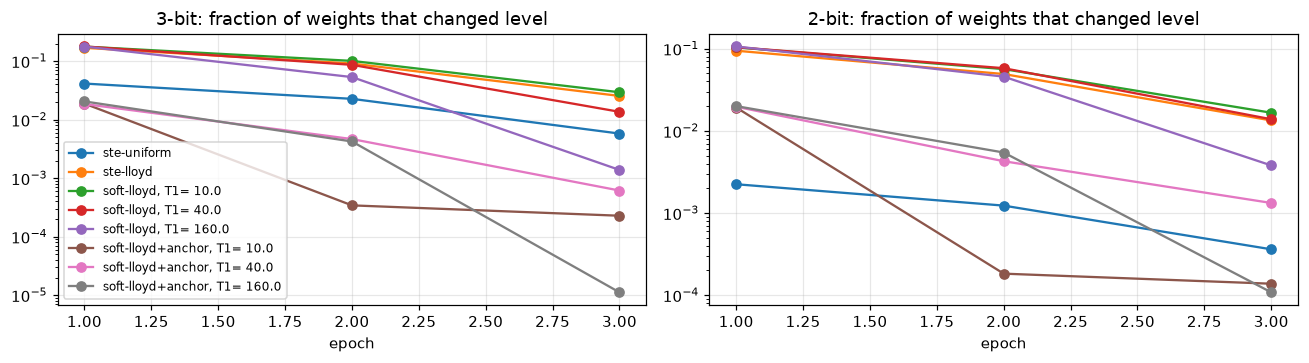

In [ ]:
fig, axs = plt.subplots(1, len(BITS), figsize=(12, 3.4))
for ax, b in zip(axs, BITS):
    for name in CONTENDERS:
        if name == "fp32": continue
        if name in ("soft-lloyd", "soft-lloyd+anchor"):
            for t1 in T1:
                ax.semilogy(range(1, EPOCHS + 1), H[(name, b, t1)]["flips"], "o-", label=f"{name}, T1= {t1}")
        else:
            ax.semilogy(range(1, EPOCHS + 1), H[(name, b)]["flips"], "o-", label=name)
    ax.set_title(f"{b}-bit: fraction of weights that changed level"); ax.set_xlabel("epoch")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## Step 6 · Where do the weights end up?

Histogram of $|w - Q(w)| / \Delta$ at the end of training: 0 means the latent weight sits on its level, 0.5 means on a
limit (one noisy step from flipping). For the deployed model only $Q(w)$ matters, but this distance says how
**decided** each weight is, which is what freezing (notebook 05) exploits.

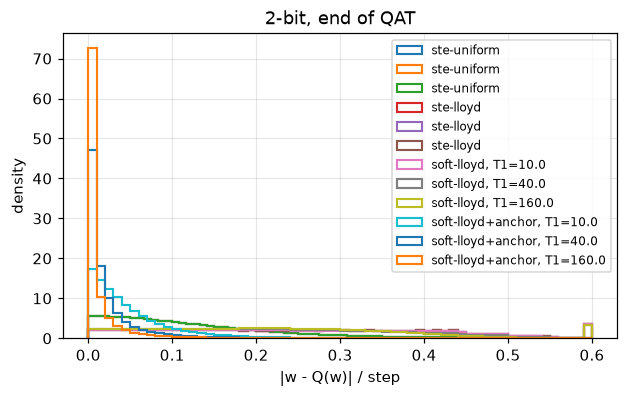

In [13]:
b = BITS[-1]
plt.figure(figsize=(6.5, 3.6))
for name in CONTENDERS:
    if name == "fp32": continue
    for t1 in T1:
        if name in ("soft-lloyd", "soft-lloyd+anchor"):
            plt.hist(np.clip(H[(name, b,t1)]["dist"], 0, 0.6), bins=60, histtype="step", density=True, lw=1.4, label=f"{name}, T1={t1}")
        else:
            plt.hist(np.clip(H[(name, b)]["dist"], 0, 0.6), bins=60, histtype="step", density=True, lw=1.4, label=name)    
plt.xlabel("|w - Q(w)| / step"); plt.ylabel("density"); plt.title(f"{b}-bit, end of QAT"); plt.legend(fontsize=8); plt.show()

### What this v1.0 run shows (one seed; numbers in the cells above)

* **The budget matters more than the quantizer at 3 bits:** the float model goes from 69.0 % to 81.4 % with the same 3
  epochs, and every contender gains about as much. Without the `fp32` row, QAT would look like it *improves* accuracy.
* **2 bits:** STE-Lloyd 80.6 % (almost float), soft-Lloyd 76.4 %, soft + anchor 74.9 %, STE-uniform 56.8 %. Again
  level placement first; the soft staircase with this schedule loses to STE on the same levels. This is the same ranking
  as on the tiny LM (06) and TIMIT (07).
* The soft contenders **drop in the first epoch** (hard accuracy 61–69 %) because at $T\approx2$ the soft model they
  train is far from the hard one we evaluate; they catch up as $T$ grows. A schedule that starts at a larger $T$, or a
  shorter soft phase, is the first thing to try (exercise 2).

### Reading the results
Look at your own table and figures; one seed and 3 epochs is a **smoke test**, not a result. Questions to ask:
* Does `ste-lloyd` beat `ste-uniform`? Then the level placement alone matters.
* Does `soft-lloyd` beat `ste-lloyd`? Then the gradient through the staircase matters.
* Does the anchor change accuracy, oscillation, or only the distance histogram?

### Exercises (this is where the real study starts)
1. Run 3 seeds per contender and report mean ± std. Which differences survive?
2. Sweep $T_1 \in \{10, 40, 160\}$ and $\lambda \in \{0.1, 1, 10\}$.
3. Add LSQ (learned step size, Esser et al. 2020, arXiv:1902.08153) as a stronger STE baseline: uniform levels whose
   scale is a trainable parameter.
4. Give the float model a longer schedule (10 epochs) and redo everything: are the gaps the same on a better model?

**Next:** [05 · Anchors and freezing](05_anchor_freeze.ipynb).